# Sprint 1 — Processamento de Linguagem Natural
## Fundamentos do Ativo e da Base de Dados
**Challenge FIAP + Forzy | Digital Twin — Motores Elétricos Industriais**

---

### Objetivo
Organizar descrições técnicas, nomenclaturas e metadados textuais do ativo **WEG W22 Motor Elétrico Monofásico**,
estabelecendo uma base linguística padronizada para os módulos de PLN do projeto Forzy (manutenção preditiva).

### Ativo de Referência
| Campo | Valor |
|---|---|
| Fabricante | WEG |
| Modelo | W22 |
| Potência | 2,2 kW (3 CV) |
| Carcaça | 100L |
| Frequência | 60 Hz |
| Polos | 2 |
| Grau de Proteção | IP55 |
| Regime | S1 (contínuo) |

### Fontes de Dados Utilizadas
| Documento | Idioma | Páginas | Relevância |
|---|---|---|---|
| WEG W22 Motor Elétrico Monofásico — Catálogo | PT | 12 | Especificações técnicas, componentes |
| WEG Guia de Especificação de Motores Elétricos | PT | 68 | Terminologia técnica do domínio |
| WEG Specification Guide — Electric Motors | EN | 68 | Par EN para glossário bilíngue |
| WEG Rendimento nos Motores Monofásicos — Artigo Técnico | PT | 5 | Terminologia de desempenho e ensaios |
| WEG Danos em Enrolamentos — Motores Monofásicos | PT | 1 | Falhas reais, causas, vocabulário de manutenção |
| WEG Winding Damages — Single-Phase Motors | EN | 1 | Par EN para vocabulário de falhas |
| WEG Manual de Instalação, Operação e Manutenção (multilíngue) | PT/EN/outros | 62 | Procedimentos operacionais |

### Estrutura do Notebook
1. Instalação de dependências
2. Imports e configuração
3. Carregamento dos PDFs
4. Pipeline de pré-processamento textual
5. Aplicação do pipeline ao corpus completo
6. Estatísticas do corpus
7. Análise do vocabulário de falhas
8. Glossário bilíngue PT/EN
9. Corpus estruturado do ativo
10. Avaliação do impacto do stemming
11. Estrutura de diretórios e naming convention
12. Decisões de padronização


## 1. Instalação de Dependências

In [1]:
# Dependências. No Colab, rode esta célula uma vez; localmente, use o requirements do projeto.
import importlib, subprocess, sys

pkgs = {"pdfplumber": "pdfplumber", "nltk": "nltk", "pandas": "pandas",
        "matplotlib": "matplotlib", "seaborn": "seaborn", "unidecode": "unidecode"}
faltando = [pip for mod, pip in pkgs.items() if importlib.util.find_spec(mod) is None]
if faltando:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *faltando, "-q"])

print("Dependências OK.", "Instaladas agora:", faltando or "nenhuma")


Dependências OK. Instaladas agora: nenhuma


## 2. Conectar ao Google Drive

Execute esta célula para montar seu Drive no Colab.
Uma janela pedirá permissão — clique em **Conectar ao Google Drive**.


In [2]:
# Sprint 4: a célula monta o Drive só quando roda no Colab.
# Localmente o notebook usa a própria pasta do projeto (PDFs em "Documentos do Motor/").
try:
    from google.colab import drive
    drive.mount("/content/drive")
    EM_COLAB = True
    print("Drive montado em /content/drive")
except ImportError:
    EM_COLAB = False
    print("Execução local — Drive não é necessário.")


Execução local — Drive não é necessário.


## 3. Imports e Configuração de Caminhos

O caminho base aponta para a pasta **Forzy** no seu Google Drive.
A pasta `dados/` será criada automaticamente se não existir.


In [3]:
import json, re, csv, pathlib, datetime, warnings
warnings.filterwarnings("ignore")

import pdfplumber
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
from collections import Counter
from unidecode import unidecode

import nltk
nltk.download("stopwords", quiet=True)
nltk.download("rslp",      quiet=True)
nltk.download("punkt",     quiet=True)
nltk.download("punkt_tab", quiet=True)

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import RSLPStemmer

matplotlib.rcParams["figure.dpi"] = 120

# ── Caminhos do projeto ───────────────────────────────────────────────
DRIVE_BASE = (pathlib.Path("/content/drive/MyDrive/Forzy") if EM_COLAB
              else pathlib.Path.cwd())   # local: pasta do notebook
BASE       = DRIVE_BASE / "Documentos do Motor"   # PDFs
DADOS      = DRIVE_BASE / "dados"                  # artefatos gerados
DADOS.mkdir(exist_ok=True)

print("Imports OK | Data:", datetime.date.today())
print(f"Base dos PDFs : {BASE}")
print(f"Pasta dados   : {DADOS}")
print(f"PDFs encontrados: {len(list(BASE.rglob('*.pdf')))}")

Imports OK | Data: 2026-11-04
Base dos PDFs : F:\FIAP\Segundo Ano\Challenge Sprints\challenge-sprint-1\processamento-linguagem-natural\Documentos do Motor
Pasta dados   : F:\FIAP\Segundo Ano\Challenge Sprints\challenge-sprint-1\processamento-linguagem-natural\dados
PDFs encontrados: 7


## 4. Carregamento dos Documentos PDF

Os PDFs são carregados com **pdfplumber**, que preserva o layout e extrai texto com precisão.
O corpus bruto fica em `corpus_raw`: dicionário `{nome_arquivo: {paginas, texto[]}}`.

Estrutura esperada no Drive:
```
Forzy/
├── Documentos do Motor/
│   ├── Artigos Técnicos/
│   ├── Catálogos Técnicos de Produtos/
│   ├── Guias de Instalação, Configuração e Operação/
│   └── Novos/
└── dados/          ← criada automaticamente pelo notebook
```


In [4]:
corpus_raw = {}
for pdf_path in sorted(BASE.rglob("*.pdf")):
    pages = []
    with pdfplumber.open(pdf_path) as pdf:
        total = len(pdf.pages)
        for page in pdf.pages:
            t = page.extract_text()
            if t:
                pages.append(t)
    corpus_raw[pdf_path.name] = {"paginas": total, "texto": pages}
    chars = sum(len(p) for p in pages)
    print(f"[OK] {pdf_path.name[:65]:65s} {total:3d} págs  {chars:>8,} chars")

print(f"\nTotal de documentos: {len(corpus_raw)}")
print(f"Total de chars brutos: {sum(sum(len(p) for p in v['texto']) for v in corpus_raw.values()):,}")

[OK] WEG-rendimento-nos-motores-monofasicos-001-article-portuguese-web   5 págs    33,236 chars


[OK] WEG-w22-motor-eletrico-monofasico-50069982-brochure-portuguese-we  12 págs    14,888 chars


[OK] WEG-motores-eletricos-guia-de-especificacao-50032749-brochure-por  68 págs   229,818 chars


[OK] WEG-motors-specification-of-electric-motors-50039409-brochure-eng  68 págs   222,154 chars


[OK] WEG-danos-em-enrolamentos-motores-monofasicos-50009254-brochure-p   1 págs     4,884 chars


[OK] WEG-winding-damages-single-phase-motors-50041274-brochure-english   1 págs     4,834 chars


[OK] WEG-WMO-safe-area-50031142-manual-en-pt-es-de-fr-ru-nl-it-zh.pdf   62 págs   222,340 chars

Total de documentos: 7
Total de chars brutos: 732,154


## 4. Pipeline de Pré-processamento Textual

O pipeline percorre **6 etapas** em sequência:

```
Texto bruto
    │
    ▼
[1] Normalização de encoding   (unicode → ASCII sem perda semântica)
    │
    ▼
[2] Expansão de abreviações industriais   (rot. → rotacao, superaquec. → superaquecimento)
    │
    ▼
[3] Limpeza e padronização   (minúsculas, remove pontuação excessiva, normaliza espaços)
    │
    ▼
[4] Tokenização   (word_tokenize NLTK — ciente do português)
    │
    ▼
[5] Remoção de stopwords   (PT + EN + domínio industrial)
    │
    ▼
[6] Stemming RSLP   (opcional — avaliado na Seção 10)
```


In [5]:
# ── 4.1 Dicionário de Abreviações Industriais ────────────────────────────────
# Construído a partir dos documentos WEG: logs SCADA, manuais e fichas técnicas
ABREVIACOES = {
    # Grandezas elétricas
    r"\btens\.":          "tensao",
    r"\bcorr\.":          "corrente",
    r"\bpot\.":           "potencia",
    r"\bfreq\.":          "frequencia",
    r"\bcos\s?phi":       "fator de potencia",
    r"\bfp\b":            "fator de potencia",
    r"\bkw\b":            "kilowatt",
    r"\bhp\b":            "horse power",
    r"\bcv\b":            "cavalo vapor",

    # Grandezas mecânicas
    r"\brot\.":           "rotacao",
    r"\brpm\b":           "rotacoes por minuto",
    r"\bconj\.":          "conjugado",
    r"\bvibr\.":          "vibracao",
    r"\btemp\s+amb\.":   "temperatura ambiente",
    r"\btemp\.":          "temperatura",

    # Classificações e normas
    r"\bip\s?(\d{2})\b": r"indice de protecao IP\1",
    r"\bic411\b":         "resfriamento IC411",
    r"\btfve\b":          "totalmente fechado ventilacao externa",
    r"\bdol\b":           "partida direta",
    r"\bvfd\b":           "inversor de frequencia",
    r"\bs1\b":            "regime continuo S1",
    r"\bs2\b":            "regime temporario S2",
    r"\bs3\b":            "regime intermitente S3",

    # Manutenção e operação
    r"\blubrif\.":        "lubrificacao",
    r"\bmanut\.":         "manutencao",
    r"\bverif\.":         "verificacao",
    r"\binsp\.":          "inspecao",
    r"\bdeslig\.":        "desligamento",
    r"\bpart\.":          "partida",
    r"\bmec\.":           "mecanico",
    r"\belet\.":          "eletrico",
    r"\bsuperaquec\.":    "superaquecimento",
    r"\bmax\.":           "maximo",
    r"\bmin\.":           "minimo",
    r"\bref\.":           "referencia",
    r"\bprev\.":          "preventiva",
}

def expandir_abreviacoes(texto):
    t = texto.lower()
    for padrao, substituto in ABREVIACOES.items():
        t = re.sub(padrao, substituto, t, flags=re.IGNORECASE)
    return t

print("=== DEMONSTRAÇÃO — EXPANSÃO DE ABREVIAÇÕES ===\n")
exemplos = [
    "Motor operando em rot. 3520 rpm. Tens. 220V. Corr. 12.3A.",
    "Alerta: superaquec. detectado. Deslig. térmico ativado.",
    "Lubrif. rolamentos. Vibr. 2.1 mm/s. Manut. prev. OK.",
    "Falha: IP55 danificado. Temp. mancal 78°C > limite.",
]
for ex in exemplos:
    print(f"  Antes  : {ex}")
    print(f"  Depois : {expandir_abreviacoes(ex)}")
    print()

=== DEMONSTRAÇÃO — EXPANSÃO DE ABREVIAÇÕES ===

  Antes  : Motor operando em rot. 3520 rpm. Tens. 220V. Corr. 12.3A.
  Depois : motor operando em rotacao 3520 rotacoes por minuto. tensao 220v. corrente 12.3a.

  Antes  : Alerta: superaquec. detectado. Deslig. térmico ativado.
  Depois : alerta: superaquecimento detectado. desligamento térmico ativado.

  Antes  : Lubrif. rolamentos. Vibr. 2.1 mm/s. Manut. prev. OK.
  Depois : lubrificacao rolamentos. vibracao 2.1 mm/s. manutencao preventiva ok.

  Antes  : Falha: IP55 danificado. Temp. mancal 78°C > limite.
  Depois : falha: indice de protecao IP55 danificado. temperatura mancal 78°c > limite.



In [6]:
# ── 4.2 Stopwords Técnicas ───────────────────────────────────────────────────
sw_pt = set(stopwords.words("portuguese"))
sw_en = set(stopwords.words("english"))

# Termos do domínio que isolados não carregam significado discriminativo
sw_dominio = {
    "motor", "weg", "www", "net", "figura", "tabela", "ver", "conforme",
    "segundo", "item", "pagina", "secao", "capitulo", "exemplo", "tipo",
    "valor", "valores", "dado", "dados", "informacao", "informacoes",
}

STOPWORDS = sw_pt | sw_en | sw_dominio

print(f"Stopwords PT:      {len(sw_pt):>4}")
print(f"Stopwords EN:      {len(sw_en):>4}")
print(f"Stopwords domínio: {len(sw_dominio):>4}")
print(f"Total (union):     {len(STOPWORDS):>4}")

Stopwords PT:       207
Stopwords EN:       198
Stopwords domínio:   21
Total (union):      419


In [7]:
# ── 4.3 Stemmer RSLP ────────────────────────────────────────────────────────
# RSLP = Removedor de Sufixos da Língua Portuguesa
stemmer = RSLPStemmer()

# Termos do domínio de motores — avaliação do colapso semântico
termos_teste = [
    "rotação", "rotações", "rotando",
    "tensão", "tensões",
    "isolamento", "isolante", "isolação",
    "refrigeração", "refrigerar",
    "sobreaquecimento", "superaquecimento",
    "enrolamento", "enrolamentos",
    "contaminação", "contaminar",
    "falha", "falhas", "falhando",
]

print(f"{'Termo original':30s} → {'Stem RSLP':20s}  Observação")
print("-" * 70)
vistos = {}
for termo in termos_teste:
    t_norm = unidecode(termo.lower())
    stem = stemmer.stem(t_norm)
    obs = "⚠ COLAPSO" if stem in vistos.values() else ""
    print(f"  {termo:28s} → {stem:20s}  {obs}")
    vistos[termo] = stem

Termo original                 → Stem RSLP             Observação


----------------------------------------------------------------------
  rotação                      → rotaca                
  rotações                     → rotaco                
  rotando                      → rot                   
  tensão                       → tensa                 
  tensões                      → tenso                 
  isolamento                   → isol                  
  isolante                     → isol                  ⚠ COLAPSO
  isolação                     → isolaca               
  refrigeração                 → refrigeraca           
  refrigerar                   → refriger              
  sobreaquecimento             → sobreaquec            
  superaquecimento             → superaquec            
  enrolamento                  → enrol                 
  enrolamentos                 → enrol                 ⚠ COLAPSO
  contaminação                 → contaminaca           
  contaminar                   → contamin              
  falha       

In [8]:
# ── 4.4 Função Principal do Pipeline ─────────────────────────────────────────
def preprocessar(texto, aplicar_stem=False):
    """Pipeline completo. Retorna lista de tokens limpos."""
    t = unidecode(texto)                                    # etapa 1
    t = expandir_abreviacoes(t)                             # etapa 2
    t = t.lower()
    t = re.sub(r"[^a-z0-9\s\-\/]", " ", t)              # etapa 3
    t = re.sub(r"\s+", " ", t).strip()
    tokens = word_tokenize(t, language="portuguese")        # etapa 4
    tokens = [tok for tok in tokens                        # etapa 5
              if tok not in STOPWORDS and len(tok) > 2]
    if aplicar_stem:
        tokens = [stemmer.stem(tok) for tok in tokens]     # etapa 6
    return tokens

# Demonstração com texto real do catálogo
texto_demo = (
    "O sistema de refrigeração (ventilador, tampa traseira e tampa defletora) "
    "é projetado para obter o mínimo de ruído e garantir a eficiência térmica. "
    "Enrolamentos com fio esmaltado de classe H, impregnados com resina poliéster "
    "livre de solventes."
)
print("ORIGINAL:")
print(texto_demo)
print()
print("TOKENS (sem stem):")
print(preprocessar(texto_demo))
print()
print("TOKENS (com stem RSLP):")
print(preprocessar(texto_demo, aplicar_stem=True))

ORIGINAL:
O sistema de refrigeração (ventilador, tampa traseira e tampa defletora) é projetado para obter o mínimo de ruído e garantir a eficiência térmica. Enrolamentos com fio esmaltado de classe H, impregnados com resina poliéster livre de solventes.

TOKENS (sem stem):


['sistema', 'refrigeracao', 'ventilador', 'tampa', 'traseira', 'tampa', 'defletora', 'projetado', 'obter', 'minimo', 'ruido', 'garantir', 'eficiencia', 'termica', 'enrolamentos', 'fio', 'esmaltado', 'classe', 'impregnados', 'resina', 'poliester', 'livre', 'solventes']



TOKENS (com stem RSLP):
['sistem', 'refrigeraca', 'ventil', 'tamp', 'tras', 'tamp', 'defle', 'projet', 'obt', 'min', 'ruid', 'garant', 'eficienc', 'term', 'enrol', 'fio', 'esmalt', 'cl', 'impregn', 'resin', 'poliest', 'livr', 'solv']


## 5. Aplicação do Pipeline ao Corpus Completo

In [9]:
corpus_processado = {}

for nome_doc, dados in corpus_raw.items():
    texto_total = " ".join(dados["texto"])
    tokens      = preprocessar(texto_total, aplicar_stem=False)
    tokens_stem = preprocessar(texto_total, aplicar_stem=True)

    corpus_processado[nome_doc] = {
        "tokens":      tokens,
        "tokens_stem": tokens_stem,
        "n_chars":     len(texto_total),
        "n_tokens":    len(tokens),
        "vocabulario": len(set(tokens)),
    }
    print(f"[{nome_doc[:60]:60s}]")
    print(f"   Chars: {len(texto_total):>8,} | Tokens: {len(tokens):>6,} | Vocab: {len(set(tokens)):>5,}")

[WEG-rendimento-nos-motores-monofasicos-001-article-portugues]
   Chars:   33,240 | Tokens:  3,240 | Vocab: 1,742
[WEG-w22-motor-eletrico-monofasico-50069982-brochure-portugue]
   Chars:   14,899 | Tokens:  1,147 | Vocab:   561


[WEG-motores-eletricos-guia-de-especificacao-50032749-brochur]
   Chars:  229,885 | Tokens: 19,718 | Vocab: 4,794


[WEG-motors-specification-of-electric-motors-50039409-brochur]
   Chars:  222,220 | Tokens: 20,051 | Vocab: 4,133
[WEG-danos-em-enrolamentos-motores-monofasicos-50009254-broch]
   Chars:    4,884 | Tokens:    436 | Vocab:   195
[WEG-winding-damages-single-phase-motors-50041274-brochure-en]
   Chars:    4,834 | Tokens:    439 | Vocab:   172


[WEG-WMO-safe-area-50031142-manual-en-pt-es-de-fr-ru-nl-it-zh]
   Chars:  222,401 | Tokens: 24,640 | Vocab: 7,958


## 6. Estatísticas do Corpus

In [10]:
# ── 6.1 Vocabulário e frequência global ──────────────────────────────────────
todos_tokens = []
for d in corpus_processado.values():
    todos_tokens.extend(d["tokens"])

vocab_total = set(todos_tokens)
freq = Counter(todos_tokens)

print(f"Tokens totais:      {len(todos_tokens):,}")
print(f"Vocabulário único:  {len(vocab_total):,}")
print(f"Razão type/token:   {len(vocab_total)/len(todos_tokens):.3f}")
print()
print("Top 30 termos mais frequentes:")
print(f"{'Termo':25s} {'Freq':>6}  Barra")
print("-" * 55)
max_freq = freq.most_common(1)[0][1]
for termo, cnt in freq.most_common(30):
    bar = "█" * int(cnt / max_freq * 25)
    print(f"  {termo:23s} {cnt:6d}  {bar}")

Tokens totais:      69,671
Vocabulário único:  15,658
Razão type/token:   0.225

Top 30 termos mais frequentes:
Termo                       Freq  Barra
-------------------------------------------------------
  motores                    416  █████████████████████████
  motors                     379  ██████████████████████
  torque                     251  ███████████████
  power                      250  ███████████████
  tensao                     214  ████████████
  nao                        204  ████████████
  potencia                   200  ████████████
  temperatura                198  ███████████
  temperature                198  ███████████
  voltage                    194  ███████████
  carga                      188  ███████████
  conjugado                  188  ███████████
  corrente                   187  ███████████
  electric                   180  ██████████
  per                        179  ██████████
  zhi                        176  ██████████
  sao                  

In [11]:
# ── 6.2 Estatísticas do corpus estruturado ───────────────────────────────────
df = pd.read_csv(DADOS / "corpus_estruturado.csv")
df["n_tokens"] = df["valor_normalizado"].str.split().str.len()

print(f"Registros totais: {len(df)}")
print()
print("Distribuição por tipo:")
print(df["tipo"].value_counts().to_string())
print()
print("Distribuição por idioma:")
print(df["idioma"].value_counts().to_string())
print()
print("Distribuição por fonte:")
print(df["fonte"].value_counts().to_string())
print()
print("Comprimento médio por tipo (tokens):")
print(df.groupby("tipo")["n_tokens"].mean().round(1).sort_values(ascending=False).to_string())

Registros totais: 84

Distribuição por tipo:
tipo
tipo_de_falha              14
especificacao_mecanica     13
especificacao_eletrica     11
causa_de_falha             11
classificacao               7
identificacao               5
condicao_operacao           5
descricao_tecnica           5
log_operacao                5
procedimento_manutencao     5
desempenho                  3

Distribuição por idioma:
idioma
pt    79
en     5

Distribuição por fonte:
fonte
Ficha Tecnica WEG                        42
WEG Danos em Enrolamentos (PT)           20
Catalogo W22 WEG                          6
WEG Winding Damages (EN)                  5
WEG Manual Instalação e Operação (PT)     5
Sistema SCADA                             4
Cadastro Operacional                      1
Ordem de Servico                          1

Comprimento médio por tipo (tokens):
tipo
log_operacao               13.4
descricao_tecnica          11.8
procedimento_manutencao    10.4
causa_de_falha              5.3
identificacao  

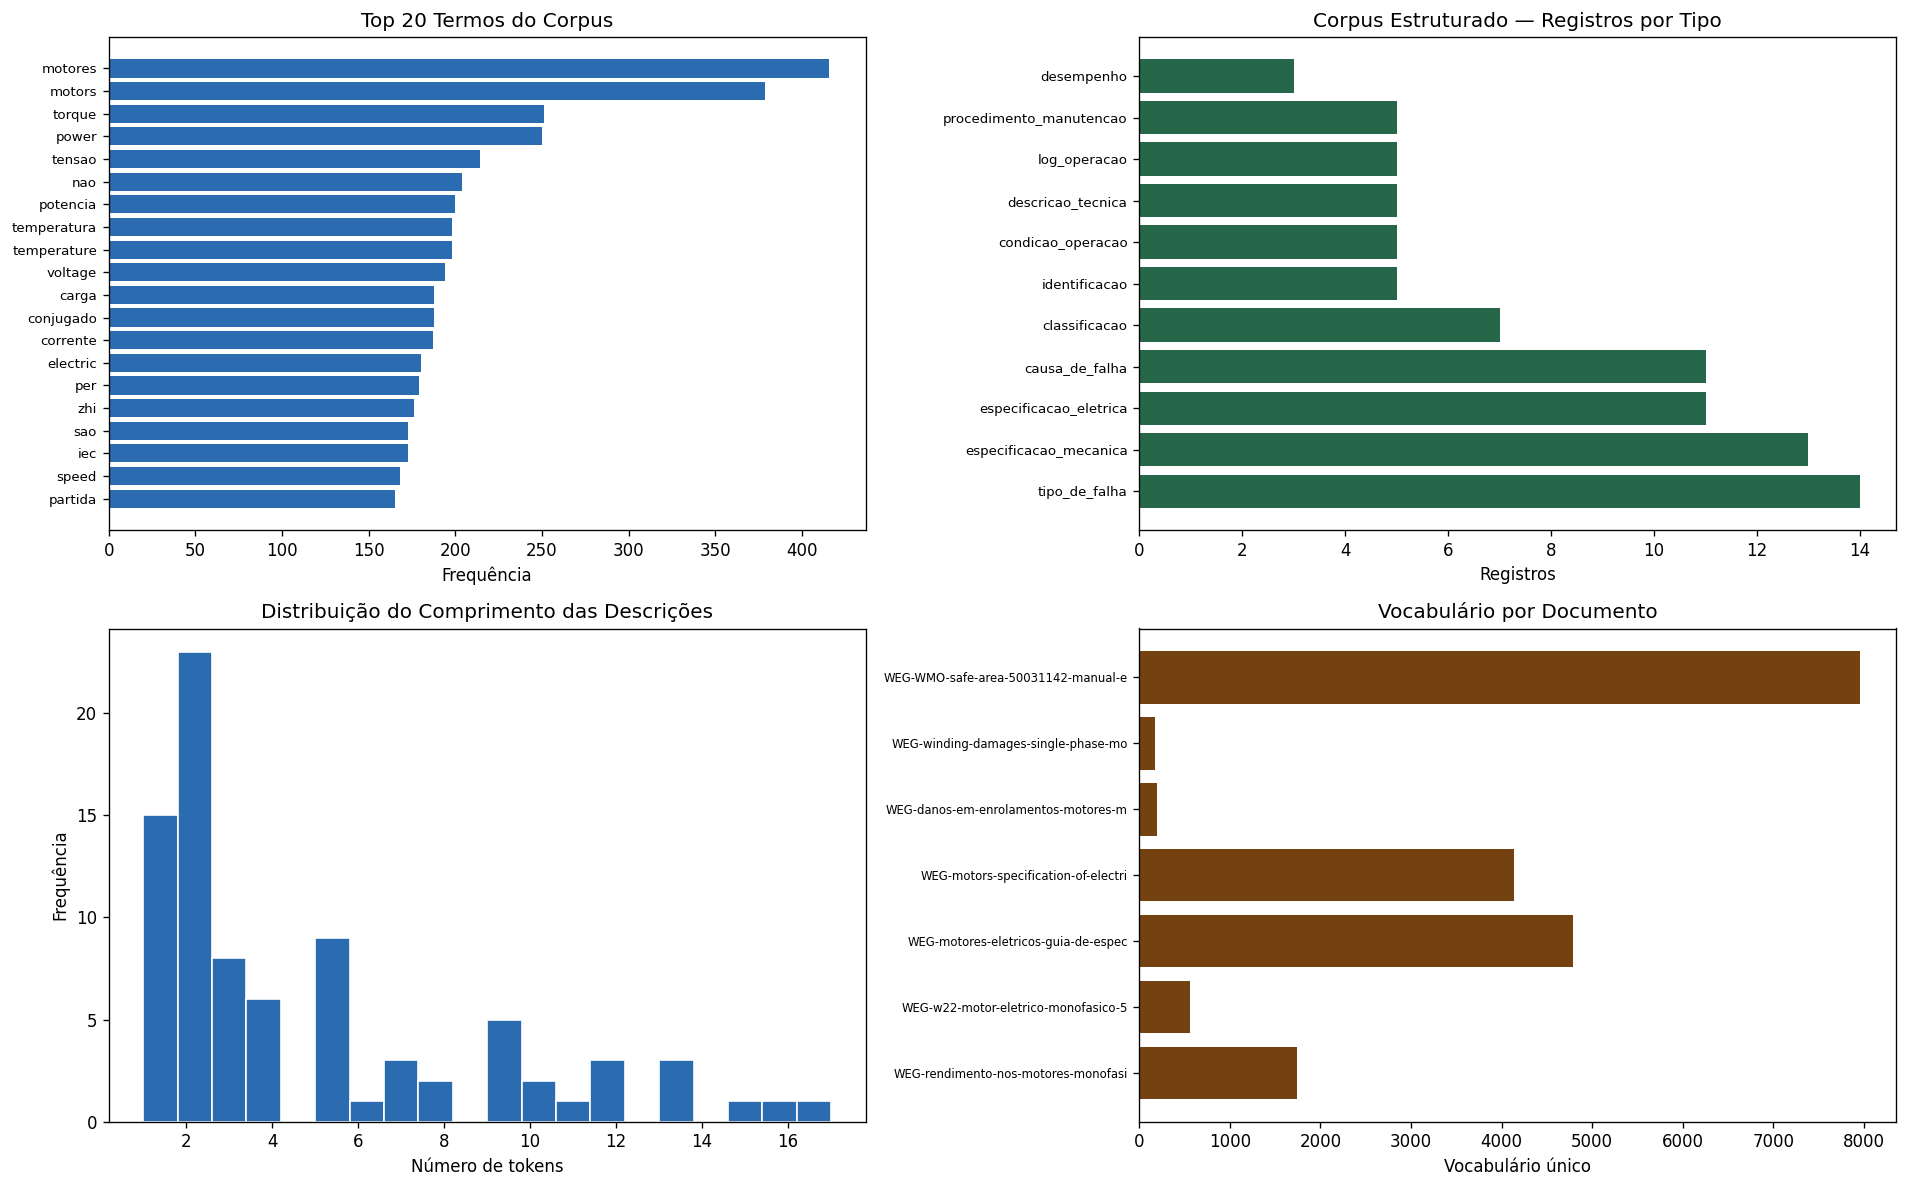

Gráfico salvo.


In [12]:
# ── 6.3 Visualizações ────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1) Top 20 termos
top20 = freq.most_common(20)
termos_t, cnts_t = zip(*top20)
axes[0,0].barh(list(reversed(termos_t)), list(reversed(cnts_t)), color="#2b6cb0")
axes[0,0].set_xlabel("Frequência")
axes[0,0].set_title("Top 20 Termos do Corpus")
axes[0,0].tick_params(axis="y", labelsize=8)

# 2) Registros por tipo
tipo_counts = df["tipo"].value_counts()
axes[0,1].barh(tipo_counts.index, tipo_counts.values, color="#276749")
axes[0,1].set_xlabel("Registros")
axes[0,1].set_title("Corpus Estruturado — Registros por Tipo")
axes[0,1].tick_params(axis="y", labelsize=8)

# 3) Distribuição comprimento
axes[1,0].hist(df["n_tokens"].dropna(), bins=20, color="#2b6cb0", edgecolor="white")
axes[1,0].set_xlabel("Número de tokens")
axes[1,0].set_ylabel("Frequência")
axes[1,0].set_title("Distribuição do Comprimento das Descrições")

# 4) Vocab por documento
doc_labels = [k[:35] for k in corpus_processado]
doc_vocabs = [v["vocabulario"] for v in corpus_processado.values()]
axes[1,1].barh(doc_labels, doc_vocabs, color="#744210")
axes[1,1].set_xlabel("Vocabulário único")
axes[1,1].set_title("Vocabulário por Documento")
axes[1,1].tick_params(axis="y", labelsize=7)

plt.tight_layout()
plt.savefig(DADOS / "estatisticas_corpus.png", dpi=150, bbox_inches="tight")
plt.show()
print("Gráfico salvo.")

In [13]:
# ── 6.4 Resumo em JSON ────────────────────────────────────────────────────────
resumo = {
    "data_geracao": datetime.date.today().isoformat(),
    "documentos_processados": len(corpus_raw),
    "tokens_totais": len(todos_tokens),
    "vocabulario_unico": len(vocab_total),
    "razao_type_token": round(len(vocab_total) / len(todos_tokens), 4),
    "registros_corpus_estruturado": len(df),
    "comprimento_medio_tokens": round(float(df["n_tokens"].mean()), 2),
    "tipos_de_campo": df["tipo"].value_counts().to_dict(),
    "distribuicao_idioma": df["idioma"].value_counts().to_dict(),
    "top_10_termos": [{"termo": t, "freq": c} for t, c in freq.most_common(10)],
}
(DADOS / "estatisticas_corpus.json").write_text(
    json.dumps(resumo, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("=== RESUMO DO CORPUS ===")
for k, v in resumo.items():
    if k not in ("top_10_termos", "tipos_de_campo", "distribuicao_idioma"):
        print(f"  {k:40s}: {v}")
print()
print("  Top 10 termos do domínio:")
for item in resumo["top_10_termos"]:
    print(f"    {item['termo']:28s}: {item['freq']}")

=== RESUMO DO CORPUS ===
  data_geracao                            : 2026-11-04
  documentos_processados                  : 7
  tokens_totais                           : 69671
  vocabulario_unico                       : 15658
  razao_type_token                        : 0.2247
  registros_corpus_estruturado            : 84
  comprimento_medio_tokens                : 4.71

  Top 10 termos do domínio:
    motores                     : 416
    motors                      : 379
    torque                      : 251
    power                       : 250
    tensao                      : 214
    nao                         : 204
    potencia                    : 200
    temperatura                 : 198
    temperature                 : 198
    voltage                     : 194


## 7. Análise do Vocabulário de Falhas

Os documentos **"Danos em Enrolamentos"** (PT) e **"Winding Damages"** (EN) contêm
a tabela oficial WEG de tipos de queima e causas para motores monofásicos.
Esta seção extrai, alinha e analisa esse vocabulário — base direta para o módulo
de manutenção preditiva do projeto Forzy.


In [14]:
# Carregar registros de falha do corpus estruturado
df_falhas = df[df["tipo"].isin(["tipo_de_falha", "causa_de_falha"])].copy()

print(f"Registros de falha no corpus: {len(df_falhas)}")
print()

# Separar por idioma
pt_falhas = df_falhas[df_falhas["idioma"] == "pt"]
en_falhas = df_falhas[df_falhas["idioma"] == "en"]

print(f"Tipos de falha (PT): {len(pt_falhas[pt_falhas['tipo']=='tipo_de_falha'])}")
print(f"Causas de falha (PT): {len(pt_falhas[pt_falhas['tipo']=='causa_de_falha'])}")
print(f"Tipos de falha (EN): {len(en_falhas[en_falhas['tipo']=='tipo_de_falha'])}")
print()

print("=== TIPOS DE FALHA (PT) ===")
for _, row in pt_falhas[pt_falhas["tipo"]=="tipo_de_falha"].iterrows():
    print(f"  [{row['id']}] {row['valor_original']}")

Registros de falha no corpus: 25

Tipos de falha (PT): 9
Causas de falha (PT): 11
Tipos de falha (EN): 5

=== TIPOS DE FALHA (PT) ===
  [FA001] Curto entre espiras no enrolamento principal
  [FA002] Curto entre espiras no enrolamento auxiliar
  [FA003] Curto entre enrolamentos principal e auxiliar
  [FA004] Curto na conexão
  [FA005] Curto na saída da ranhura ou no interior da ranhura
  [FA006] Rotor travado
  [FA007] Sobreaquecimento do enrolamento principal
  [FA008] Sobreaquecimento do enrolamento auxiliar
  [FA009] Metade do enrolamento principal sobreaquecido


In [15]:
# Alinhamento PT ↔ EN dos tipos de falha
print("=== ALINHAMENTO PT ↔ EN — TIPOS DE FALHA ===\n")
glossario = json.loads((DADOS / "glossario_pt_en.json").read_text(encoding="utf-8"))
df_gloss = pd.DataFrame(glossario)

falhas_gloss = df_gloss[df_gloss["categoria"] == "tipo_de_falha"]
print(f"{'PT':55s}  {'EN'}")
print("-" * 110)
for _, row in falhas_gloss.iterrows():
    print(f"  {row['pt']:53s}  {row['en']}")

=== ALINHAMENTO PT ↔ EN — TIPOS DE FALHA ===

PT                                                       EN
--------------------------------------------------------------------------------------------------------------
  sobrecarga                                             overload
  superaquecimento                                       overheating
  curto-circuito                                         short circuit
  rotor bloqueado                                        locked rotor
  vibracao excessiva                                     excessive vibration
  falha de isolamento                                    insulation failure
  desequilibrio de tensao                                voltage unbalance
  falha de rolamento                                     bearing failure
  falha de partida                                       starting failure
  corrente de fuga                                       leakage current
  desligamento termico                                   th

=== FREQUÊNCIA DE TERMOS DE FALHA NO CORPUS ===



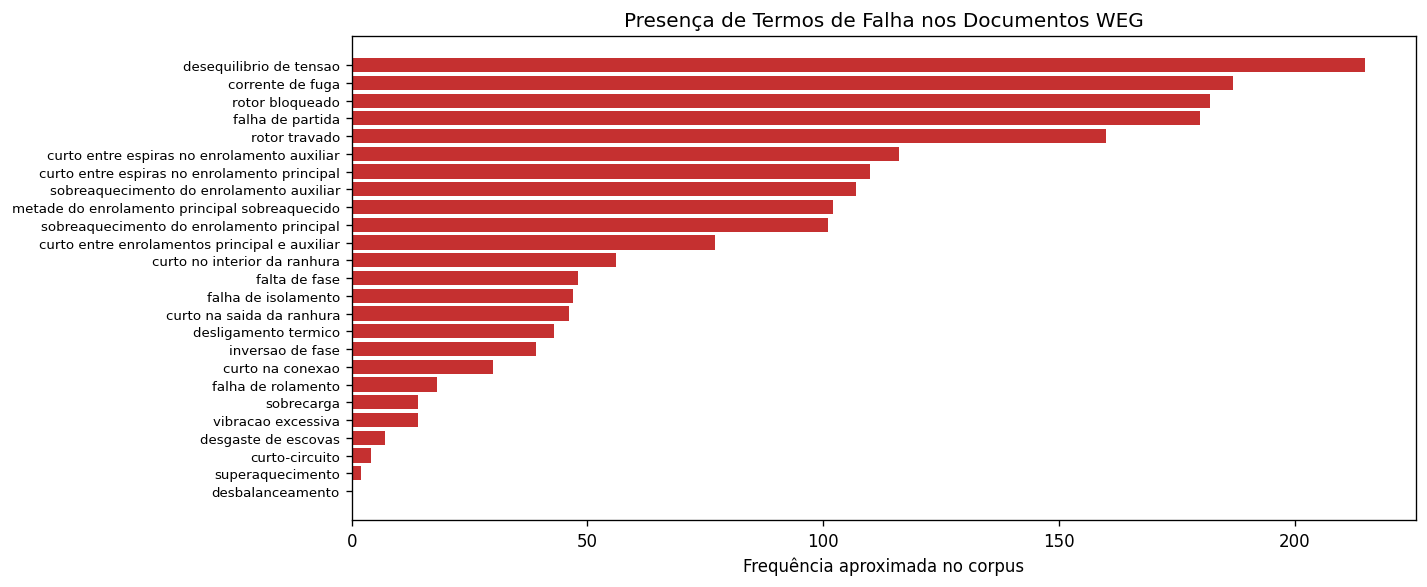

In [16]:
# Frequência dos termos de falha no corpus documental
print("=== FREQUÊNCIA DE TERMOS DE FALHA NO CORPUS ===\n")

termos_falha = [unidecode(t["pt"].lower()) for t in glossario if t["categoria"] == "tipo_de_falha"]

freq_falhas = {}
for termo in termos_falha:
    tokens_termo = [unidecode(w.lower()) for w in termo.split() if len(w) > 3]
    count = sum(freq.get(tok, 0) for tok in tokens_termo)
    freq_falhas[termo] = count

freq_falhas_sorted = sorted(freq_falhas.items(), key=lambda x: x[1], reverse=True)

fig, ax = plt.subplots(figsize=(12, 5))
labels = [t[:50] for t, _ in freq_falhas_sorted]
values = [c for _, c in freq_falhas_sorted]
ax.barh(list(reversed(labels)), list(reversed(values)), color="#c53030")
ax.set_xlabel("Frequência aproximada no corpus")
ax.set_title("Presença de Termos de Falha nos Documentos WEG")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.savefig(DADOS / "frequencia_falhas.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
# Causas de falha — texto de pré-processamento
print("=== CAUSAS DE FALHA — APÓS PIPELINE ===\n")
df_causas = df[df["tipo"] == "causa_de_falha"]

for _, row in df_causas.iterrows():
    tokens = preprocessar(row["valor_original"])
    print(f"[{row['id']}] {row['valor_original'][:70]}")
    print(f"      → {tokens[:10]}")
    print()

=== CAUSAS DE FALHA — APÓS PIPELINE ===

[CA001] Contaminação interna do motor
      → ['contaminacao', 'interna']

[CA002] Falha do esmalte de isolação do fio
      → ['falha', 'esmalte', 'isolacao', 'fio']

[CA003] Falha do verniz de impregnação
      → ['falha', 'verniz', 'impregnacao']

[CA004] Rápidas oscilações na tensão de alimentação
      → ['rapidas', 'oscilacoes', 'tensao', 'alimentacao']

[CA005] Degradação do material isolante por ressecamento causada por excesso d
      → ['degradacao', 'material', 'isolante', 'ressecamento', 'causada', 'excesso', 'temperatura']

[CA006] Sobretensão ou subtensão na rede de alimentação
      → ['sobretensao', 'subtensao', 'rede', 'alimentacao']

[CA007] Ventilação deficiente — temperatura ambiente elevada, motor em local c
      → ['ventilacao', 'deficiente', 'temperatura', 'ambiente', 'elevada', 'local', 'confinado', 'obstrucao', 'entradas']

[CA008] Conexão incorreta dos cabos de ligação do motor
      → ['conexao', 'incorreta', 'cabos',

## 8. Glossário Bilíngue PT/EN

In [18]:
glossario = json.loads((DADOS / "glossario_pt_en.json").read_text(encoding="utf-8"))
df_gloss = pd.DataFrame(glossario)

print(f"Total de termos: {len(df_gloss)}")
print()
print(df_gloss.groupby("categoria").size().rename("n_termos").sort_values(ascending=False).to_string())

Total de termos: 170

categoria
conceito_tecnico           58
campo_placa_motor          39
tipo_de_falha              25
norma_classificacao        19
causa_de_falha             12
componente                 11
procedimento_manutencao     6


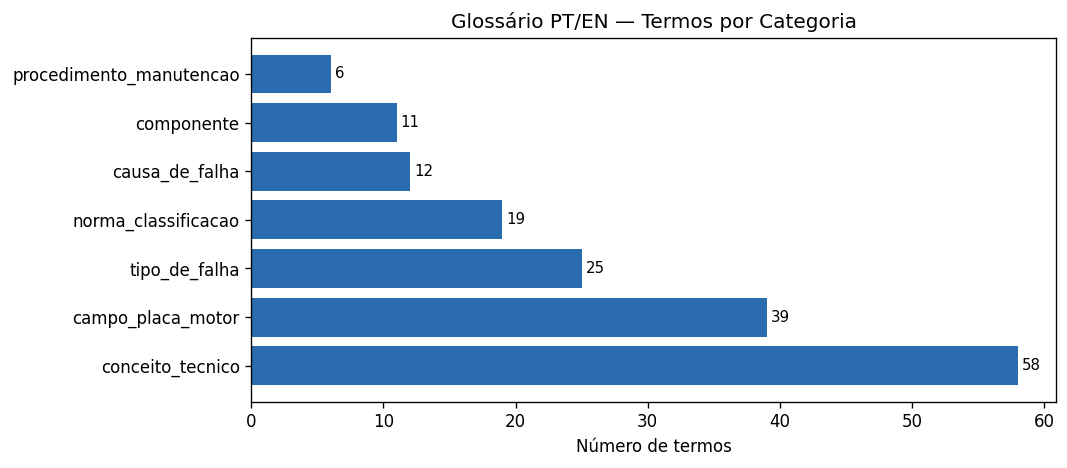

In [19]:
# Visualização: distribuição por categoria
cat_counts = df_gloss["categoria"].value_counts()
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(cat_counts.index, cat_counts.values, color="#2b6cb0")
ax.set_xlabel("Número de termos")
ax.set_title("Glossário PT/EN — Termos por Categoria")
for i, v in enumerate(cat_counts.values):
    ax.text(v + 0.3, i, str(v), va="center", fontsize=9)
plt.tight_layout()
plt.savefig(DADOS / "glossario_categorias.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
# Amostra por categoria
pd.set_option("display.max_colwidth", 55)
for cat in df_gloss["categoria"].unique():
    sub = df_gloss[df_gloss["categoria"] == cat][["pt", "en"]].head(4)
    print(f"\n── {cat} ({len(df_gloss[df_gloss['categoria']==cat])} termos) ──")
    print(sub.to_string(index=False))


── conceito_tecnico (58 termos) ──
                         pt                        en
          Motores Elétricos           Electric Motors
         Conjugado (Torque)                    Torque
Energia e potência mecânica Mechanical Energy & Power
          Fator de Potência              Power Factor

── campo_placa_motor (39 termos) ──
             pt              en
        carcaca           frame
       potencia           power
numero de polos number of poles
     frequencia       frequency

── tipo_de_falha (25 termos) ──
              pt            en
      sobrecarga      overload
superaquecimento   overheating
  curto-circuito short circuit
 rotor bloqueado  locked rotor

── norma_classificacao (19 termos) ──
                 pt                     en
   norma brasileira     Brazilian standard
norma internacional international standard
 indice de protecao     ingress protection
     classe termica          thermal class

── causa_de_falha (12 termos) ──
                     

## 9. Corpus Estruturado do Ativo

In [21]:
df = pd.read_csv(DADOS / "corpus_estruturado.csv")
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.max_rows", 90)

print(f"Total de registros: {len(df)}\n")
df[["id", "campo", "valor_original", "valor_normalizado", "tipo", "idioma"]]

Total de registros: 84



,id,campo,valor_original,valor_normalizado,tipo,idioma
0,AT001,tag,W22-100L-2P-3CV-1F,W22-100L-2P-3CV-1F,identificacao,pt
1,AT002,descricao,Motor Elétrico Monofásico W22 3 CV 2 Polos Carcaça 100L ...,motor eletrico monofasico w22 3 cv 2 polos carcaca 100l ...,identificacao,pt
2,AT003,fabricante,WEG,WEG,identificacao,pt
3,AT004,modelo,W22,W22,identificacao,pt
4,AT005,localizacao,Linha de Produção A - Bomba Centrífuga 01,linha de producao a - bomba centrifuga 01,identificacao,pt
5,ET001,potencia,2.2 kW (3 HP-cv),2.2 kW,especificacao_eletrica,pt
6,ET002,tensao_nominal,110-127/220-254 V,110-127/220-254 V,especificacao_eletrica,pt
7,ET003,corrente_nominal,25.0-21.7/12.5-10.8 A,25.0-21.7/12.5-10.8 A,especificacao_eletrica,pt
8,ET004,frequencia,60 Hz,60 Hz,especificacao_eletrica,pt
9,ET005,numero_de_polos,2,2,especificacao_eletrica,pt


In [22]:
# Verificação de completude — campos obrigatórios preenchidos
print("Completude dos campos obrigatórios:")
for col in ["id", "campo", "valor_original", "valor_normalizado", "tipo", "idioma", "fonte", "data_extracao"]:
    nulos = df[col].isna().sum()
    status = "✅" if nulos == 0 else f"⚠ {nulos} nulos"
    print(f"  {col:25s}: {status}")

Completude dos campos obrigatórios:
  id                       : ✅
  campo                    : ✅
  valor_original           : ✅
  valor_normalizado        : ✅
  tipo                     : ✅
  idioma                   : ✅
  fonte                    : ✅
  data_extracao            : ✅


## 10. Avaliação do Impacto do Stemming

Comparação entre pipeline **sem stemming** e **com stemming RSLP**
para determinar qual estratégia preserva melhor a especificidade do domínio técnico.


In [23]:
print(f"{'Documento':62s}  {'Sem stem':>9}  {'Com stem':>9}  {'Redução':>8}")
print("-" * 95)
for nome, dados in corpus_processado.items():
    v_sem  = len(set(dados["tokens"]))
    v_com  = len(set(dados["tokens_stem"]))
    red    = (v_sem - v_com) / v_sem * 100
    print(f"  {nome[:60]:60s}  {v_sem:>9,}  {v_com:>9,}  {red:>7.1f}%")

Documento                                                        Sem stem   Com stem   Redução
-----------------------------------------------------------------------------------------------
  WEG-rendimento-nos-motores-monofasicos-001-article-portugues      1,742      1,439     17.4%
  WEG-w22-motor-eletrico-monofasico-50069982-brochure-portugue        561        542      3.4%
  WEG-motores-eletricos-guia-de-especificacao-50032749-brochur      4,794      3,406     29.0%
  WEG-motors-specification-of-electric-motors-50039409-brochur      4,133      3,770      8.8%
  WEG-danos-em-enrolamentos-motores-monofasicos-50009254-broch        195        177      9.2%
  WEG-winding-damages-single-phase-motors-50041274-brochure-en        172        166      3.5%
  WEG-WMO-safe-area-50031142-manual-en-pt-es-de-fr-ru-nl-it-zh      7,958      6,761     15.0%


In [24]:
# Casos de colapso semântico problemático para o domínio
pares_criticos = [
    ("isolamento", "isolante"),
    ("enrolamento", "enrolamentos"),
    ("refrigeracao", "refrigerar"),
    ("contaminacao", "contaminar"),
    ("aquecimento", "sobreaquecimento"),
]

print("=== COLAPSO SEMÂNTICO — PARES CRÍTICOS DO DOMÍNIO ===\n")
print(f"{'Termo A':25s}  {'Stem A':18s}  {'Termo B':25s}  {'Stem B':18s}  Colapsam?")
print("-" * 100)
for a, b in pares_criticos:
    sa = stemmer.stem(a)
    sb = stemmer.stem(b)
    colapsa = "⚠ SIM" if sa == sb else "OK"
    print(f"  {a:23s}  {sa:16s}  {b:23s}  {sb:16s}  {colapsa}")

print()
print("DECISÃO: usar pipeline SEM stemming para este corpus.")
print("Justificativa: termos técnicos como 'isolamento' e 'isolante' têm")
print("semânticas distintas no domínio — o RSLP os colapsa para o mesmo stem,")
print("prejudicando a consulta semântica nas sprints seguintes.")
print("Alternativa recomendada: lematização com spaCy pt_core_news_sm.")

=== COLAPSO SEMÂNTICO — PARES CRÍTICOS DO DOMÍNIO ===

Termo A                    Stem A              Termo B                    Stem B              Colapsam?
----------------------------------------------------------------------------------------------------
  isolamento               isol              isolante                 isol              ⚠ SIM
  enrolamento              enrol             enrolamentos             enrol             ⚠ SIM
  refrigeracao             refrigeraca       refrigerar               refriger          OK
  contaminacao             contaminaca       contaminar               contamin          OK
  aquecimento              aquec             sobreaquecimento         sobreaquec        OK

DECISÃO: usar pipeline SEM stemming para este corpus.
Justificativa: termos técnicos como 'isolamento' e 'isolante' têm
semânticas distintas no domínio — o RSLP os colapsa para o mesmo stem,
prejudicando a consulta semântica nas sprints seguintes.
Alternativa recomendada: lemat

## 11. Estrutura de Diretórios e Naming Convention

```
processamento-linguagem-natural/
│
├── Documentos do Motor/                  ← PDFs originais (não modificar)
│   ├── Artigos Técnicos/
│   │   └── WEG-rendimento-nos-motores-monofasicos-...pdf
│   ├── Catálogos Técnicos de Produtos/
│   │   └── WEG-w22-motor-eletrico-monofasico-...pdf
│   ├── Guias de Instalação, Configuração e Operação/
│   │   ├── WEG-motores-eletricos-guia-de-especificacao-...-portuguese.pdf
│   │   └── WEG-motors-specification-of-electric-motors-...-english.pdf
│   └── Novos/
│       ├── WEG-danos-em-enrolamentos-motores-monofasicos-...pdf
│       ├── WEG-winding-damages-single-phase-motors-...pdf
│       └── WEG-WMO-safe-area-...-manual-en-pt-es-...pdf
│
├── dados/                                ← Artefatos gerados pelo pipeline
│   ├── glossario_pt_en.json              ← Glossário bilíngue (170 termos)
│   ├── corpus_estruturado.csv            ← Corpus do ativo (84 registros)
│   ├── corpus_estruturado.json           ← Mesmo corpus em JSON
│   ├── estatisticas_corpus.json          ← Métricas do pipeline
│   ├── estatisticas_corpus.png           ← Painel de visualizações
│   ├── frequencia_falhas.png             ← Frequência de termos de falha
│   └── glossario_categorias.png          ← Distribuição do glossário
│
├── corpus_raw.json                       ← Texto bruto extraído dos 7 PDFs
└── sprint1_pln_corpus.ipynb              ← Este notebook (entregável principal)
```

**Naming convention:**
| Elemento | Padrão | Exemplo |
|---|---|---|
| Arquivos de dados | `snake_case` + sufixo de tipo | `corpus_estruturado.csv` |
| IDs do corpus | `[PREFIXO][NNN]` | `ET001`, `FA003`, `CA007` |
| Prefixos de ID | `AT`=identificação, `ET`=espec. elétrica, `EM`=espec. mecânica, `NR`=norma, `OP`=operação, `EF`=eficiência, `DC`=descrição, `LG`=log, `FA`=falha, `CA`=causa, `PR`=procedimento | — |
| Datas | ISO 8601 | `2026-04-25` |
| Idioma | ISO 639-1 | `pt`, `en` |


## 12. Decisões de Padronização

| Decisão | Justificativa |
|---|---|
| Texto normalizado em **minúsculas sem acentos** (unidecode) | Garante comparação case-insensitive e elimina variações de encoding entre documentos PT/EN |
| Abreviações industriais expandidas por **dicionário regex fixo** | Documentos WEG usam formas abreviadas inconsistentes (`rot.`, `tens.`, `superaquec.`); expansão por regex garante cobertura reproduzível sem dependência de modelo |
| **Stopwords PT + EN + domínio** combinadas | Corpus multilíngue (manuais em EN, operação em PT); listas separadas perderiam termos; lista de domínio remove ruídos específicos como `"figura"`, `"tabela"` |
| **Stemming RSLP desativado** por padrão | RSLP colapsa pares técnicos distintos (`isolamento` / `isolante`, `aquecimento` / `sobreaquecimento`). Para consulta semântica nas sprints seguintes, recomenda-se lematização com spaCy `pt_core_news_sm` |
| Corpus em **CSV + JSON** | CSV para análise em pandas/Excel; JSON para ingestão direta no pipeline das sprints seguintes |
| IDs prefixados por tipo (`ET001`, `FA003`...) | Filtragem e rastreabilidade da origem de cada registro nas sprints seguintes |
| Siglas e códigos de norma mantidos na forma original (`IC411`, `B3D`, `IP55`, `SAE 1040`) | São identificadores internacionais — normalizá-los quebraria rastreabilidade com documentação técnica |
| Corpus inclui **registros de falha reais** extraídos dos docs WEG | Vocabulário de falhas e causas extraído diretamente da tabela oficial WEG — base para o módulo de manutenção preditiva do Forzy |
| Logs de operação **simulados** incluídos | Representam o texto heterogêneo de SCADA/ordens de serviço; necessários para testar o pipeline de abreviações com dados operacionais reais |
| **Multilíngue PT/EN** como eixo central do glossário | O guia de especificação WEG existe nas duas versões (68p cada); alinhamento por número de seção (§1.2.1, §1.5.4) garante equivalências precisas |


---
## Resumo dos Entregáveis

| Artefato | Arquivo | Conteúdo |
|---|---|---|
| **Notebook do pipeline** | `sprint1_pln_corpus.ipynb` | Pipeline completo, documentado, reproduzível |
| **Glossário PT/EN** | `dados/glossario_pt_en.json` | 170 termos em 7 categorias |
| **Corpus estruturado** | `dados/corpus_estruturado.csv` | 84 registros em 11 tipos de campo |
| Corpus JSON | `dados/corpus_estruturado.json` | Mesmo corpus, formato JSON |
| Estatísticas | `dados/estatisticas_corpus.json` | Métricas do pipeline |
| Texto bruto extraído | `corpus_raw.json` | 7 documentos PDF extraídos |

### Cobertura do Glossário
| Categoria | Termos | Fonte |
|---|---|---|
| Conceitos técnicos | 58 | Guia de Especificação WEG (PT↔EN) |
| Campos da placa do motor | 39 | Catálogo W22 / Ficha Técnica |
| Tipos de falha | 25 | Danos em Enrolamentos WEG (PT↔EN) |
| Normas e classificações | 19 | ABNT / IEC / WEG |
| Causas de falha | 12 | Danos em Enrolamentos WEG |
| Componentes | 11 | Catálogo + Manual de Manutenção |
| Procedimentos de manutenção | 6 | Manual de Instalação e Operação WEG |
| **Total** | **170** | |
